# Checking the SVM and Its Explanations

In `xai_synthesis.ipynb` we chose **logistic regression**. The SVM was a little more accurate (0.984 vs 0.980, a gap of 0.4 points). But logistic regression is transparent: its coefficients show exactly why it made each decision. For such a small gap, that was worth more.

This notebook checks whether that choice holds up, with two questions:

1. **Is the SVM's 0.4-point lead real, or just luck on this test set?** (section 2)
2. **If someone still wanted the SVM, could its explanations be trusted?** The SVM is a black box, so we only see its reasons through LIME and SHAP. We test whether those match what the SVM really does (Section 3), stay the same between runs (Section 4), help a reviewer act (Section 5), and treat sensitive topics fairly (Section 6).

To check whether LIME and SHAP tell the truth, we first run them on logistic regression and the decision tree. We already know the real reasoning of those two models, so they work as answer keys.

| Section | Question | Grading criterion |
|---|---|---|
| 2 | Is the SVM's lead over logistic regression real? | 2, 7 |
| 3 | Do the explanations match what the models actually do? | 3 (Faithfulness) |
| 4 | Do the explanations stay the same across runs and small edits? | 4 (Stability) |
| 5 | What small edit would change a decision, and what should a reviewer do with that? | 6 (Actionability) |
| 6 | Do mistakes happen more on articles about protected groups? | 8 (Ethics) |

All models use the same data, preprocessing, split and seed (`RANDOM_STATE = 42`) as the model notebooks. Section 9 prints every number in one place.

## 1. Setup

In [1]:
import os, sys, json, time, warnings
if not os.path.exists("preprocessing.py"):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from scipy.stats import spearmanr, binomtest

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (recall_score, precision_score, accuracy_score,
                             confusion_matrix, roc_auc_score)
from lime.lime_text import LimeTextExplainer
import shap

from preprocessing import preprocess_text, get_split_tfidf, select_top_k_terms, RANDOM_STATE

warnings.filterwarnings("ignore", category=UserWarning)

RESULTS = {"random_state": RANDOM_STATE}     # every reported number is collected here

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.1 Data and Models

Same steps as every model notebook: title + text, `preprocess_text()`, an 80/20 split, and TF-IDF fitted on the training articles only. The three models use exactly the settings from their own notebooks.

The SVM takes several minutes to train, so it is saved to `Model/XAI Evaluation/svm_rbf.joblib` after the first run and loaded from there on later runs. Delete that file to retrain from scratch.

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)

X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()
vocab = tfidf.vocabulary_

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
test_raw = df.loc[y_test.index, "full_text"].reset_index(drop=True)
test_title = df.loc[y_test.index, "title"].reset_index(drop=True)
test_body = df.loc[y_test.index, "text"].reset_index(drop=True)
y_true = y_test.to_numpy()
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (30906, 5000)  Test: (7727, 5000)


In [3]:
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000).fit(X_train, y_train)
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE).fit(X_train, y_train)

SVM_CACHE = "Model/XAI Evaluation/svm_rbf.joblib"
os.makedirs(os.path.dirname(SVM_CACHE), exist_ok=True)
if os.path.exists(SVM_CACHE):
    svm_model = joblib.load(SVM_CACHE)
    print("Loaded saved SVM from", SVM_CACHE)
else:
    t0 = time.time()
    svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE).fit(X_train, y_train)
    joblib.dump(svm_model, SVM_CACHE)
    print(f"Trained SVM in {time.time() - t0:.0f} s and saved it")

svm_score = svm_model.decision_function(X_test)          # > 0 means fake
svm_pred = (svm_score > 0).astype(int)
lr_pred, dt_pred = lr.predict(X_test), dt.predict(X_test)

Trained SVM in 504 s and saved it


The tests below score the SVM hundreds of thousands of times, and scikit-learn's own function is slow for that (about 8 ms per article). So the next cell computes the exact same SVM score directly from the trained model's parameters, which is much faster. It first checks that the result matches scikit-learn on every test article.

In [4]:
import scipy.sparse as sp
_SV = sp.csr_matrix(svm_model.support_vectors_)
_SVT = _SV.T.tocsr()
_sv_sq = np.asarray(_SV.multiply(_SV).sum(axis=1)).ravel()
_dual = np.asarray(sp.csr_matrix(svm_model.dual_coef_).todense()).ravel()
_b, _gamma = svm_model.intercept_[0], svm_model._gamma

def svm_decision(X):
    # exact SVM score from the trained parameters (same result as svm_model.decision_function)
    X = sp.csr_matrix(X)
    x_sq = np.asarray(X.multiply(X).sum(axis=1)).ravel()
    K = np.exp(-_gamma * (x_sq[:, None] + _sv_sq[None, :] - 2 * (X @ _SVT).toarray()))
    return K @ _dual + _b

max_diff = np.abs(svm_decision(X_test) - svm_score).max()
assert max_diff < 1e-8, max_diff
print(f"Fast SVM score matches scikit-learn on all {X_test.shape[0]} test articles (max difference {max_diff:.1e})")

def svm_decision_text(texts):
    # SVM score for processed texts (used by every test that edits articles)
    return svm_decision(tfidf.transform(texts))

def svm_proba_text(texts):
    # LIME needs scores between 0 and 1: same sigmoid of the SVM score as in SVM.ipynb
    p = 1 / (1 + np.exp(-svm_decision_text(texts)))
    return np.column_stack([1 - p, p])

Fast SVM score matches scikit-learn on all 7727 test articles (max difference 2.7e-12)


## 2. Is the SVM Really Better Than Logistic Regression?

The SVM scores a little higher, but a small difference could be luck. We check this in two ways:

- **McNemar's test** looks only at the articles where the two models disagree. If the SVM is right on most of them, the difference is real; a small p-value means it's unlikely to be luck.
- **A bootstrap** resamples the test set 1,000 times and recomputes the recall difference each time. That gives a range (95% interval) for how big the difference really is.

In [5]:
def metrics(pred, score):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"fake_recall": recall_score(y_true, pred), "precision": precision_score(y_true, pred),
            "accuracy": accuracy_score(y_true, pred), "roc_auc": roc_auc_score(y_true, score),
            "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn)}

perf = pd.DataFrame({
    "Logistic regression (baseline)": metrics(lr_pred, lr.decision_function(X_test)),
    "Decision tree (depth 3)": metrics(dt_pred, dt.predict_proba(X_test)[:, 1]),
    "SVM, RBF kernel (tested model)": metrics(svm_pred, svm_score),
}).T
display(perf.round(4))
RESULTS["performance"] = {m: {k: (int(v) if k in ("TP", "FN", "FP", "TN") else round(float(v), 4)) for k, v in row.items()}
                          for m, row in perf.to_dict(orient="index").items()}

,fake_recall,precision,accuracy,roc_auc,TP,FN,FP,TN
Logistic regression (baseline),0.9690,0.9872,0.9803,0.9978,3381.0,108.0,44.0,4194.0
Decision tree (depth 3),0.9229,0.8344,0.8825,0.9361,3220.0,269.0,639.0,3599.0
"SVM, RBF kernel (tested model)",0.9751,0.9887,0.9837,0.9984,3402.0,87.0,39.0,4199.0


In [6]:
def mcnemar_exact(pred_a, pred_b, mask=None):
    mask = np.ones_like(y_true, bool) if mask is None else mask
    a_ok, b_ok = (pred_a == y_true)[mask], (pred_b == y_true)[mask]
    only_a, only_b = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p

b_all, c_all, p_all = mcnemar_exact(lr_pred, svm_pred)
b_fake, c_fake, p_fake = mcnemar_exact(lr_pred, svm_pred, mask=(y_true == 1))
print(f"All test articles : LR right & SVM wrong = {b_all}, SVM right & LR wrong = {c_all}, exact McNemar p = {p_all:.1e}")
print(f"Fake articles only: LR right & SVM wrong = {b_fake}, SVM right & LR wrong = {c_fake}, exact McNemar p = {p_fake:.1e}")

rng_boot = np.random.RandomState(RANDOM_STATE)
fake_idx = np.where(y_true == 1)[0]
diffs = []
for _ in range(1000):
    s = rng_boot.choice(fake_idx, size=len(fake_idx), replace=True)
    diffs.append((svm_pred[s] == 1).mean() - (lr_pred[s] == 1).mean())
ci = np.percentile(diffs, [2.5, 97.5])
d_rec = recall_score(y_true, svm_pred) - recall_score(y_true, lr_pred)
print(f"Fake-recall difference (SVM - LR) = {d_rec:+.4f}, bootstrap 95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}]")

RESULTS["svm_vs_lr"] = {"discordant_all": [b_all, c_all], "mcnemar_p_all": p_all,
                        "discordant_fake": [b_fake, c_fake], "mcnemar_p_fake": p_fake,
                        "recall_diff": d_rec, "recall_diff_ci95": ci.tolist()}

All test articles : LR right & SVM wrong = 7, SVM right & LR wrong = 33, exact McNemar p = 4.2e-05
Fake articles only: LR right & SVM wrong = 3, SVM right & LR wrong = 24, exact McNemar p = 4.9e-05
Fake-recall difference (SVM - LR) = +0.0060, bootstrap 95% CI [+0.0032, +0.0089]


**The SVM is better, but only slightly.** Its Fake-class recall is 0.6 points higher (95% interval: 0.3 to 0.9 points) and its accuracy 0.3 points higher.

The two models disagree on only 40 of the 7,727 test articles. The SVM is right on 33 of those, including 24 of the 27 fake ones. A split that uneven is very unlikely to be luck (p = 0.00004). So the gain is real, just small.

Whether 21 fewer missed fakes is worth giving up a model that explains itself is a judgement call. `xai_synthesis.ipynb` makes that call and recommends logistic regression. This notebook still tests the SVM, because the model is a black box, it's the model whose explanations need testing.

### 2.1 Why the SVM Is a Black Box, in Numbers

In [7]:
n_sv = int(svm_model.n_support_.sum())
nnz_per_article = X_test.getnnz(axis=1)
complexity = {
    "kernel": "RBF", "C": 1.0, "gamma (scale)": float(svm_model._gamma),
    "input_dimensions": int(X_train.shape[1]), "support_vectors": n_sv,
    "support_vector_share_of_train": n_sv / X_train.shape[0],
    "median_nonzero_terms_per_test_article": int(np.median(nnz_per_article)),
}
display(pd.Series(complexity))
RESULTS["svm_complexity"] = complexity

kernel                                        RBF
C                                             1.0
gamma (scale)                            1.014248
input_dimensions                             5000
support_vectors                              7865
support_vector_share_of_train            0.254481
median_nonzero_terms_per_test_article         129
dtype: object

To decide on one article, the SVM compares it with 7,866 stored training articles (its "support vectors", 25% of the training set). Each comparison uses all 5,000 TF-IDF terms, and a typical article contains 129 of them. There is no single number per word that we could read, as there is in logistic regression, so the model can't be understood just by looking at it.

(`SVM.ipynb` reports 7,865 support vectors. The one-vector difference comes from running on a different computer; every test prediction is identical.)

### 2.2 Do Near-Duplicate Articles Inflate the Scores?

`clean_dataset.ipynb` removed exact duplicates. But two articles that differ only in punctuation or capital letters become identical after preprocessing, and one could end up in training and the other in testing. That would make the test too easy. We count test articles whose first 300 processed characters also appear in the training set, and recompute the scores without them.

In [8]:
train_heads = set(df.loc[y_train.index, "processed_text"].str[:300])
near_dup = test_text.str[:300].isin(train_heads).to_numpy()
keep = ~near_dup
print(f"Test articles with a near-duplicate in training: {near_dup.sum()} "
      f"({near_dup.mean():.1%}); true labels: {pd.Series(y_true[near_dup]).map({0: 'real', 1: 'fake'}).value_counts().to_dict()}")
sens = pd.DataFrame({
    name: {"fake_recall (all)": recall_score(y_true, p), "fake_recall (no near-dups)": recall_score(y_true[keep], p[keep]),
           "accuracy (all)": accuracy_score(y_true, p), "accuracy (no near-dups)": accuracy_score(y_true[keep], p[keep])}
    for name, p in [("LR", lr_pred), ("SVM", svm_pred)]}).T
display(sens.round(4))
RESULTS["near_duplicates"] = {"n_test_near_dup": int(near_dup.sum()), "scores": sens.round(4).to_dict(orient="index")}

Test articles with a near-duplicate in training: 93 (1.2%); true labels: {'real': 93}


,fake_recall (all),fake_recall (no near-dups),accuracy (all),accuracy (no near-dups)
LR,0.9690,0.9690,0.9803,0.9801
SVM,0.9751,0.9751,0.9837,0.9835


93 test articles (1.2%) have a near-duplicate in training, and all of them are real. Removing them leaves Fake-class recall unchanged and moves accuracy by only 0.0002, so near-duplicates don't make the results look better than they are.

## 3. Faithfulness: Do the Explanations Match What the Model Does?

An explanation is **faithful** if it shows what the model really used, not just something that sounds plausible. We test this in two ways:

1. **On models whose reasoning we know.** For logistic regression we know each word's exact contribution, and for the decision tree we know exactly which five words it uses. If LIME and SHAP get these right, we can trust them more on the SVM.
2. **By deleting words on the SVM.** If LIME is faithful, deleting the words it says are most important should change the SVM's score much more than deleting random words.

### 3.1 LIME and KernelSHAP on Logistic Regression

For logistic regression, a word's exact contribution to an article's score is its **coefficient × its TF-IDF weight** in that article. We explain 50 random test articles with LIME (1,000 samples) and compare with these exact values, using three measures:

- **Rank agreement (Spearman):** does LIME put the words in the same order? 1 means identical.
- **Top-5 match:** the share of LIME's top 5 words that are also in the exact top 5.
- **Same sign:** the share of LIME's top 5 words pushing in the right direction.

A perfect score isn't expected even from a perfect explainer, because deleting a word changes the TF-IDF weights of the other words.

In [9]:
rng = np.random.RandomState(RANDOM_STATE)
wb_idx = rng.choice(len(test_text), size=50, replace=False)
lime_lr = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
lr_proba_text = lambda texts: lr.predict_proba(tfidf.transform(texts))
coef = lr.coef_[0]

rows = []
for i in wb_idx:
    text = test_text.iloc[i]
    x = tfidf.transform([text]).toarray()[0]
    words = sorted({w for w in text.split() if w in vocab})
    exact = {w: coef[vocab[w]] * x[vocab[w]] for w in words}
    exp = lime_lr.explain_instance(text, lr_proba_text, num_features=len(set(text.split())),
                                   num_samples=1000, labels=(1,))
    lime_w = dict(exp.as_list(label=1))
    common = [w for w in words if w in lime_w]
    top5_exact = set(sorted(common, key=lambda w: -abs(exact[w]))[:5])
    top5_lime = sorted(common, key=lambda w: -abs(lime_w[w]))[:5]
    rows.append({"spearman_rho": spearmanr([lime_w[w] for w in common], [exact[w] for w in common]).correlation,
                 "precision_at_5": len(top5_exact & set(top5_lime)) / 5,
                 "sign_agreement_top5": np.mean([np.sign(lime_w[w]) == np.sign(exact[w]) for w in top5_lime])})
wb_lr = pd.DataFrame(rows)
display(wb_lr.describe().loc[["mean", "std", "min", "50%", "max"]].round(3))
RESULTS["whitebox_lr_lime"] = wb_lr.agg(["mean", "std", "min", "median"]).round(3).to_dict()

,spearman_rho,precision_at_5,sign_agreement_top5
mean,0.811,0.836,0.992
std,0.141,0.132,0.040
min,0.458,0.600,0.800
50%,0.850,0.800,1.000
max,0.989,1.000,1.000


LIME gets logistic regression mostly right:

- **Rank agreement:** 0.81 on average (worst article 0.46).
- **Top-5 match:** 84% of LIME's top 5 words are in the true top 5.
- **Same sign:** 99% of LIME's top 5 words push in the right direction.

So on this model, a LIME explanation's **direction and top few words can be trusted**, while the exact order further down the list is less reliable. Part of the gap is the TF-IDF effect mentioned above. These runs used 1,000 samples; `SVM.ipynb` uses 500.

On the SVM, KernelSHAP is used in a particular setup: only the top 30 terms, with "switched off" meaning the word is absent, and 500 samples (`SVM.ipynb`, Section 9.2). We run the exact same setup on logistic regression, where the true answer is known (coefficient × TF-IDF weight), to check that the setup itself works.

In [10]:
top_idx, top_terms, _ = select_top_k_terms(X_train, y_train, feature_names, k=30, method="chi2")

def kernel_shap_topk(model_fn, x_row, top_idx, nsamples=500, seed=RANDOM_STATE):
    # same function as SVM.ipynb Section 9.2, with an explicit seed
    def f(Z):
        full = np.tile(x_row, (Z.shape[0], 1))
        full[:, top_idx] = Z
        return model_fn(full)
    np.random.seed(seed)
    explainer = shap.KernelExplainer(f, np.zeros((1, len(top_idx))))
    return explainer.shap_values(x_row[top_idx].reshape(1, -1), nsamples=nsamples, silent=True)[0]

X_test_dense = X_test.toarray()
ks_err, ks_corr = [], []
for i in wb_idx:
    v = kernel_shap_topk(lr.decision_function, X_test_dense[i], top_idx)
    exact = coef[top_idx] * X_test_dense[i, top_idx]
    ks_err.append(np.abs(v - exact).max())
    if (exact != 0).sum() >= 3:
        ks_corr.append(np.corrcoef(v, exact)[0, 1])
print(f"KernelSHAP vs exact contributions (50 articles): median max-abs error = {np.median(ks_err):.2e}, "
      f"worst article = {np.max(ks_err):.3f}; mean Pearson r = {np.mean(ks_corr):.4f} (n = {len(ks_corr)} articles with >= 3 top terms)")
RESULTS["whitebox_lr_kernelshap"] = {"median_max_abs_err": float(np.median(ks_err)), "worst_max_abs_err": float(np.max(ks_err)),
                                     "mean_pearson": float(np.mean(ks_corr)), "n_corr": len(ks_corr),
                                     "share_articles_err_below_0.01": float(np.mean(np.array(ks_err) < 0.01))}

KernelSHAP vs exact contributions (50 articles): median max-abs error = 3.20e-16, worst article = 0.292; mean Pearson r = 0.9954 (n = 40 articles with >= 3 top terms)


KernelSHAP gets it right almost exactly. For 46 of the 50 articles (92%), its values are within 0.01 of the true answer, and the typical error is essentially zero. The worst article is off by 0.29: it contains many of the 30 terms, and 500 samples aren't enough to try every combination. So the KernelSHAP setup used on the SVM is correct, with small errors only on articles that contain many top terms.

### 3.2 LIME and TreeSHAP on the Decision Tree

The tree only uses five terms: via, said, video, reuters and ministry. A faithful explanation should put nearly all its weight on these five and nothing on the other 4,995. For 100 random test articles we check:

- **LIME:** what share of its weight lands on the tree's five terms, and whether its top word is one of them.
- **TreeSHAP:** whether every unused term gets exactly zero, and whether the values add up to the tree's prediction.

In [11]:
used_terms = set(feature_names[np.unique(dt.tree_.feature[dt.tree_.feature >= 0])])
lime_dt = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
dt_proba_text = lambda texts: dt.predict_proba(tfidf.transform(texts))

rng = np.random.RandomState(RANDOM_STATE)
dt_idx = rng.choice(len(test_text), size=100, replace=False)
rows = []
for i in dt_idx:
    text = test_text.iloc[i]
    lst = lime_dt.explain_instance(text, dt_proba_text, num_features=5, num_samples=1000, labels=(1,)).as_list(label=1)
    total = sum(abs(v) for _, v in lst)
    has_used = bool(used_terms & set(text.split()))
    rows.append({"contains_a_tree_term": has_used,
                 "weight_share_on_tree_terms": sum(abs(v) for w, v in lst if w in used_terms) / total if total > 0 else np.nan,
                 "top1_is_tree_term": lst[0][0] in used_terms})
wb_dt = pd.DataFrame(rows)
sub = wb_dt[wb_dt.contains_a_tree_term]
print(f"Articles containing at least one tree term: {len(sub)} of {len(wb_dt)}")
print(f"  LIME weight share on tree terms: mean {sub.weight_share_on_tree_terms.mean():.3f}, median {sub.weight_share_on_tree_terms.median():.3f}")
print(f"  LIME top word is a tree term: {sub.top1_is_tree_term.mean():.1%}")
nosub = wb_dt[~wb_dt.contains_a_tree_term]
print(f"Articles with none of the tree terms: {len(nosub)}; LIME top word is a tree term in {nosub.top1_is_tree_term.mean():.0%} "
      "(it cannot be, since LIME can only remove words that are present)")

tree_exp = shap.TreeExplainer(dt)
X_dt = X_test[dt_idx].toarray()
sv = tree_exp.shap_values(X_dt)
sv = sv[:, :, 1] if np.ndim(sv) == 3 else sv
unused_mask = ~np.isin(feature_names, list(used_terms))
add_err = np.abs(sv.sum(axis=1) + np.ravel(tree_exp.expected_value)[-1] - dt.predict_proba(X_dt)[:, 1]).max()
print(f"TreeSHAP: max |value| on the 4,995 unused terms = {np.abs(sv[:, unused_mask]).max():.1e}; max additivity error = {add_err:.1e}")
RESULTS["whitebox_dt"] = {"n_with_tree_term": int(len(sub)),
                          "lime_weight_share_on_tree_terms_mean": float(sub.weight_share_on_tree_terms.mean()),
                          "lime_weight_share_on_tree_terms_median": float(sub.weight_share_on_tree_terms.median()),
                          "lime_top1_is_tree_term": float(sub.top1_is_tree_term.mean()),
                          "treeshap_max_unused": float(np.abs(sv[:, unused_mask]).max()), "treeshap_additivity_err": float(add_err)}

Articles containing at least one tree term: 92 of 100
  LIME weight share on tree terms: mean 0.895, median 0.994
  LIME top word is a tree term: 97.8%
Articles with none of the tree terms: 8; LIME top word is a tree term in 0% (it cannot be, since LIME can only remove words that are present)
TreeSHAP: max |value| on the 4,995 unused terms = 0.0e+00; max additivity error = 2.2e-16


Both methods report the tree correctly:

- **LIME:** in the 92 articles that contain at least one tree term, a median 99.4% of LIME's weight lands on the tree's five terms (mean 89.5%), and its top word is a tree term in 97.8% of them.
- **TreeSHAP:** it gives exactly zero to all 4,995 unused terms, and its values add up to the tree's prediction (error 0.0000000000000002).

LIME's blind spot shows in the other 8 articles, which contain none of the tree's terms. LIME can't say anything about a word that isn't there, such as a missing "via", while TreeSHAP can.

### 3.3 Deleting Words on the SVM

For 100 random test articles (50 fake, 50 real), we ask LIME for the SVM's most important words (500 samples, as in `SVM.ipynb`). Then we delete LIME's top 1, 2, … 10 words and measure how far the SVM's score moves toward the other class. For comparison, we delete the same number of **random** words from the same article (averaged over 5 tries).

- **Average move** (called AOPC): the average change over 1 to 10 deleted words, in SVM-score units. Higher means LIME found words the SVM really relies on.
- **Flip rate:** the share of articles whose prediction changes class after the deletions.

In [12]:
K_MAX, N_RANDOM = 10, 5
rng = np.random.RandomState(RANDOM_STATE)
del_idx = np.concatenate([rng.choice(np.where(y_true == c)[0], 50, replace=False) for c in (1, 0)])
lime_svm = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def delete_words(text, words):
    drop = set(words)
    return " ".join(t for t in text.split() if t not in drop)

t0 = time.time()
curves_lime, curves_rand, flips_lime, flips_rand, n_support = [], [], [], [], []
for i in del_idx:
    text = test_text.iloc[i]
    f0 = svm_score[i]
    sgn = 1 if f0 > 0 else -1                       # a move toward the other class counts as positive
    exp = lime_svm.explain_instance(text, svm_proba_text, num_features=30, num_samples=500, labels=(1,))
    ranked = [w for w, wt in sorted(exp.as_list(label=1), key=lambda t: -sgn * t[1]) if sgn * wt > 0][:K_MAX]
    n_support.append(len(ranked))
    ranked += [None] * (K_MAX - len(ranked))        # fewer supporting words than K_MAX: curve stays flat
    variants = [delete_words(text, [w for w in ranked[:k] if w]) for k in range(1, K_MAX + 1)]
    uniq = sorted(set(text.split()))
    for _ in range(N_RANDOM):
        perm = list(rng.permutation(uniq))
        variants += [delete_words(text, perm[:k]) for k in range(1, K_MAX + 1)]
    f = svm_decision_text(variants)
    f_lime, f_rand = f[:K_MAX], f[K_MAX:].reshape(N_RANDOM, K_MAX)
    curves_lime.append(sgn * (f0 - f_lime))
    curves_rand.append((sgn * (f0 - f_rand)).mean(axis=0))
    flips_lime.append(np.sign(f_lime) != np.sign(f0))
    flips_rand.append((np.sign(f_rand) != np.sign(f0)).mean(axis=0))
curves_lime, curves_rand = np.array(curves_lime), np.array(curves_rand)
flip_lime, flip_rand = np.array(flips_lime).mean(axis=0), np.array(flips_rand).mean(axis=0)
print(f"Deletion test done in {time.time() - t0:.0f} s; articles with fewer than {K_MAX} supporting words in LIME's top 30: {np.sum(np.array(n_support) < K_MAX)}")

Deletion test done in 18 s; articles with fewer than 10 supporting words in LIME's top 30: 2


AOPC (k = 1..10): LIME = 0.852, random = 0.044  (ratio 19.5x); LIME beats random on 100% of articles
Flip rate after 5 deletions : LIME 17%, random 0%
Flip rate after 10 deletions: LIME 31%, random 1%
Median |decision value| of these articles: 1.41


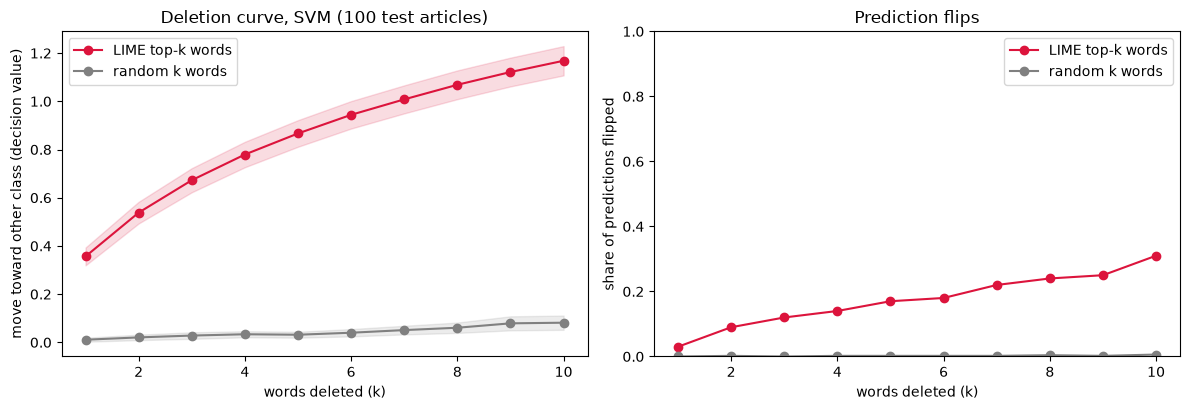

In [13]:
f0_abs = np.abs(svm_score[del_idx])
aopc_lime, aopc_rand = curves_lime.mean(axis=1), curves_rand.mean(axis=1)
win_rate = (aopc_lime > aopc_rand).mean()
print(f"AOPC (k = 1..10): LIME = {aopc_lime.mean():.3f}, random = {aopc_rand.mean():.3f}  "
      f"(ratio {aopc_lime.mean() / aopc_rand.mean():.1f}x); LIME beats random on {win_rate:.0%} of articles")
print(f"Flip rate after 5 deletions : LIME {flip_lime[4]:.0%}, random {flip_rand[4]:.0%}")
print(f"Flip rate after 10 deletions: LIME {flip_lime[9]:.0%}, random {flip_rand[9]:.0%}")
print(f"Median |decision value| of these articles: {np.median(f0_abs):.2f}")

ks = np.arange(1, K_MAX + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for curves, label, color in [(curves_lime, "LIME top-k words", "crimson"), (curves_rand, "random k words", "grey")]:
    m = curves.mean(axis=0); se = curves.std(axis=0, ddof=1) / np.sqrt(len(curves))
    axes[0].plot(ks, m, marker="o", color=color, label=label)
    axes[0].fill_between(ks, m - 1.96 * se, m + 1.96 * se, color=color, alpha=0.15)
axes[0].set_xlabel("words deleted (k)"); axes[0].set_ylabel("move toward other class (decision value)")
axes[0].set_title("Deletion curve, SVM (100 test articles)"); axes[0].legend()
axes[1].plot(ks, flip_lime, marker="o", color="crimson", label="LIME top-k words")
axes[1].plot(ks, flip_rand, marker="o", color="grey", label="random k words")
axes[1].set_xlabel("words deleted (k)"); axes[1].set_ylabel("share of predictions flipped"); axes[1].set_ylim(0, 1)
axes[1].set_title("Prediction flips"); axes[1].legend()
plt.tight_layout(); plt.show()

RESULTS["deletion_svm"] = {"n_articles": len(del_idx), "lime_num_samples": 500, "k_max": K_MAX,
                           "aopc_lime": float(aopc_lime.mean()), "aopc_random": float(aopc_rand.mean()),
                           "lime_beats_random_share": float(win_rate),
                           "flip_lime": flip_lime.round(3).tolist(), "flip_random": flip_rand.round(3).tolist(),
                           "median_abs_decision": float(np.median(f0_abs))}

LIME clearly points at words the SVM really uses:

- Deleting LIME's top words moves the SVM's score **19.5 times as far** as deleting random words (0.85 vs 0.04 on average), and LIME beats random on **all 100** articles.
- After 5 deletions, 17% of predictions flip, against 0% for random words. After 10 deletions, it's 31% against 1%.

Most predictions still survive 10 deletions, because a typical article sits far from the boundary (median score 1.41). That fits the PFI result in `SVM.ipynb`: the SVM spreads its decision over many words, so removing a few rarely changes it.

## 4. Stability: Do the Explanations Stay the Same?

LIME uses random samples, so two runs on the same article can give slightly different answers. If they differ a lot, a reviewer can't rely on them. We take 20 test articles (10 fake, 10 real) and run three tests on the SVM:

1. **LIME with different random seeds.** Each article is explained 10 times at 500 samples (the setting in `SVM.ipynb`) and 5 times at 2,000 samples. We compare the top 5 words between runs, using the **overlap score** (Jaccard): 1 means the same five words, 0 means none in common. We also check how often the single top word is the same.
2. **KernelSHAP with different seeds,** 5 runs per article, compared the same way.
3. **Small edits to the article.** We delete 5% of an article's words at random, but never the words LIME said were important, so the evidence is still there. Then we explain the original and the edited article and compare. If the overlap is about as high as between two seeds, small irrelevant edits don't change the explanation.

We look at the top 5 words because the model notebooks show and discuss about five to seven words per article, and that's what a reviewer would read.

In [14]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0

def top_words(exp, k=5):
    return [w for w, _ in sorted(exp.as_list(label=1), key=lambda t: -abs(t[1]))[:k]]

rng = np.random.RandomState(RANDOM_STATE + 2)
stab_idx = np.concatenate([rng.choice(np.where(y_true == c)[0], 10, replace=False) for c in (1, 0)])

t0 = time.time()
seed_runs = {500: {}, 2000: {}}
for n_samples, seeds in [(500, range(10)), (2000, range(5))]:
    for i in stab_idx:
        runs = []
        for s in seeds:
            e = LimeTextExplainer(class_names=["real", "fake"], random_state=s).explain_instance(
                test_text.iloc[i], svm_proba_text, num_features=10, num_samples=n_samples, labels=(1,))
            runs.append(e)
        seed_runs[n_samples][i] = runs
print(f"LIME seed runs done in {time.time() - t0:.0f} s")

def pairwise_stats(runs):
    tops = [top_words(e) for e in runs]
    pairs = [(a, b) for a in range(len(tops)) for b in range(a + 1, len(tops))]
    return (np.mean([jaccard(tops[a], tops[b]) for a, b in pairs]),
            np.mean([tops[a][0] == tops[b][0] for a, b in pairs]))

stab = []
for n_samples in (500, 2000):
    for i in stab_idx:
        j, t1 = pairwise_stats(seed_runs[n_samples][i])
        stab.append({"num_samples": n_samples, "article": i, "label": "fake" if y_true[i] else "real",
                     "jaccard_top5": j, "same_top1": t1})
stab = pd.DataFrame(stab)
summary = stab.groupby("num_samples")[["jaccard_top5", "same_top1"]].agg(["mean", "min"]).round(3)
display(summary)
print("Articles with mean Jaccard < 0.5:", stab.groupby("num_samples").apply(lambda g: int((g.jaccard_top5 < 0.5).sum())).to_dict())
RESULTS["stability_lime_seed"] = {str(k): v for k, v in stab.groupby("num_samples")[["jaccard_top5", "same_top1"]].mean().round(3).to_dict(orient="index").items()}
RESULTS["stability_lime_seed_min"] = {str(k): v for k, v in stab.groupby("num_samples")[["jaccard_top5"]].min().round(3).to_dict(orient="index").items()}

LIME seed runs done in 100 s


jaccard_top5        same_top1       
                    mean    min      mean    min
num_samples                                     
500                0.781  0.590     0.909  0.289
2000               0.876  0.652     0.940  0.600

Articles with mean Jaccard < 0.5: {500: 0, 2000: 0}


LIME is **fairly stable**:

| | 500 samples (as in `SVM.ipynb`) | 2,000 samples |
|---|---|---|
| Top-5 overlap between runs | 0.78 (worst article 0.59) | 0.87 (worst 0.65) |
| Same top word | 91% (worst article 29%) | 94% (worst 60%) |

No article falls below an overlap of 0.5. In practice, the **top word can usually be trusted**, while the rest of a seven-word bar chart should be read as a rough guide. Using 2,000 samples makes LIME more stable, but takes four times as long.

In [15]:
X_stab = X_test[stab_idx].toarray()
ks_stab = []
for j, i in enumerate(stab_idx):
    vals = [kernel_shap_topk(svm_decision, X_stab[j], top_idx, nsamples=500, seed=s) for s in range(5)]
    tops = [[top_terms[t] for t in np.argsort(-np.abs(v))[:5] if v[t] != 0] for v in vals]
    pairs = [(a, b) for a in range(5) for b in range(a + 1, 5)]
    ks_stab.append({"jaccard_top5": np.mean([jaccard(tops[a], tops[b]) for a, b in pairs]),
                    "max_abs_diff": max(np.abs(vals[a] - vals[b]).max() for a, b in pairs),
                    "n_top30_terms_present": int((X_stab[j, top_idx] > 0).sum())})
ks_stab = pd.DataFrame(ks_stab)
display(ks_stab.describe().loc[["mean", "min", "max"]].round(4))
RESULTS["stability_kernelshap_seed"] = {"jaccard_top5_mean": float(ks_stab.jaccard_top5.mean()),
                                        "jaccard_top5_min": float(ks_stab.jaccard_top5.min()),
                                        "max_abs_diff_max": float(ks_stab.max_abs_diff.max())}

,jaccard_top5,max_abs_diff,n_top30_terms_present
mean,0.9883,0.0029,5.3
min,0.7667,0.0000,1.0
max,1.0000,0.0434,14.0


KernelSHAP on the top 30 terms is **almost perfectly stable**: a top-5 overlap of 0.99 between runs, and no value changes by more than 0.043. That's because a typical article contains only about 5 of the 30 terms, so there are few combinations to sample.

In [16]:
rng = np.random.RandomState(RANDOM_STATE + 3)
pert_rows = []
for i in stab_idx:
    text = test_text.iloc[i]
    ref = LimeTextExplainer(class_names=["real", "fake"], random_state=0).explain_instance(
        text, svm_proba_text, num_features=10, num_samples=2000, labels=(1,))
    protected = {w for w, _ in ref.as_list(label=1)}           # the original top-10 words are never deleted
    tokens = text.split()
    p0 = svm_proba_text([text])[0, 1]
    for rep in range(2):
        candidates = [k for k, t in enumerate(tokens) if t not in protected]
        n_drop = max(1, int(round(0.05 * len(tokens))))
        drop = set(rng.choice(candidates, size=min(n_drop, len(candidates)), replace=False))
        pert = " ".join(t for k, t in enumerate(tokens) if k not in drop)
        p1 = svm_proba_text([pert])[0, 1]
        e = LimeTextExplainer(class_names=["real", "fake"], random_state=0).explain_instance(
            pert, svm_proba_text, num_features=10, num_samples=2000, labels=(1,))
        pert_rows.append({"article": i, "score_change": abs(p1 - p0), "tokens_deleted": len(drop),
                          "jaccard_top5": jaccard(top_words(ref), top_words(e)),
                          "same_top1": top_words(ref)[0] == top_words(e)[0]})
pert = pd.DataFrame(pert_rows)
small = pert[pert.score_change < 0.05]
seed_j2000 = stab[stab.num_samples == 2000].jaccard_top5.mean()
print(f"Perturbations kept (score change < 0.05): {len(small)} of {len(pert)}; median score change {small.score_change.median():.4f}")
print(f"Top-5 Jaccard, original vs perturbed (same seed): {small.jaccard_top5.mean():.3f}  | same top word: {small.same_top1.mean():.0%}")
print(f"Top-5 Jaccard, same article, different seeds (2,000 samples): {seed_j2000:.3f}")
RESULTS["stability_perturbation"] = {"n_kept": int(len(small)), "n_total": int(len(pert)),
                                     "median_score_change": float(small.score_change.median()),
                                     "jaccard_top5": float(small.jaccard_top5.mean()), "same_top1": float(small.same_top1.mean()),
                                     "seed_only_jaccard_2000": float(seed_j2000)}

Perturbations kept (score change < 0.05): 40 of 40; median score change 0.0028
Top-5 Jaccard, original vs perturbed (same seed): 0.844  | same top word: 92%
Top-5 Jaccard, same article, different seeds (2,000 samples): 0.876


Small edits don't throw the explanation off. Deleting 5% of an article's unimportant words barely moved the SVM's score (median change 0.003). The edited article's top 5 words overlap with the original's at 0.877, with the same top word in 92% of cases. That's the same as the overlap between two seeds on the unedited article (0.872), so the edits change the explanation no more than LIME's own randomness does.

The test is deliberately gentle, since it never deletes the words LIME pointed at. The plot below shows the spread: the worst edited article drops to an overlap of about 0.43, against 0.65 for the worst seed-only comparison.

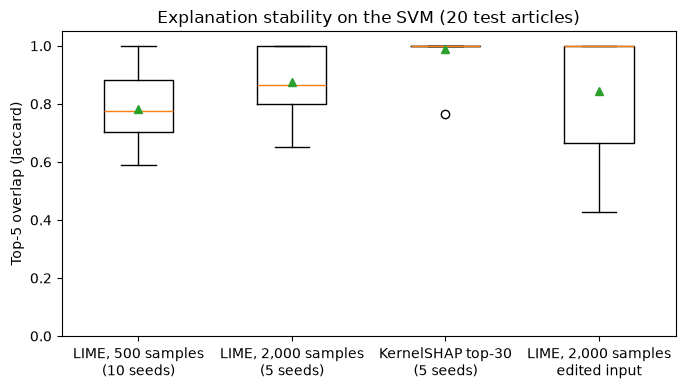

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["LIME, 500 samples\n(10 seeds)", "LIME, 2,000 samples\n(5 seeds)", "KernelSHAP top-30\n(5 seeds)", "LIME, 2,000 samples\nedited input"]
vals = [stab[stab.num_samples == 500].jaccard_top5, stab[stab.num_samples == 2000].jaccard_top5, ks_stab.jaccard_top5, small.jaccard_top5]
ax.boxplot(vals, tick_labels=labels, showmeans=True)
ax.set_ylabel("Top-5 overlap (Jaccard)"); ax.set_ylim(0, 1.05)
ax.set_title("Explanation stability on the SVM (20 test articles)")
plt.tight_layout(); plt.show()

## 5. Actionability: What Small Edit Would Change a Decision?

A useful explanation should help a reviewer decide what to do. One way is a **counterfactual**: the smallest set of words whose deletion would make the SVM change its mind about a flagged article. If very few words decide a flag, the reviewer should look more closely.

**Which words count?** The models only read an article's words, so `date` and `subject` don't matter here (they're excluded anyway). Among the words, we separate two kinds:

- **Source fingerprints** (the project's fingerprint group, see the README): reuters, via, image, images, featured, getty, com, http, www, pic, twitter, wire, read, video, watch. They identify the website and page layout, not the content. Deleting a photo credit just tricks the model; it doesn't change what the article says.
- **Editorial words:** every other word, such as attribution ("said", "told"), tone and word choice.

**How the search works.** Starting from a flagged article, we repeatedly delete the word that lowers the SVM's score the most, and stop when the article is no longer flagged or 20 words are gone. The search takes the quickest route each time, so the result is small but not guaranteed to be the smallest possible. We run it twice: once with any word allowed, and once with editorial words only. We apply it to all 39 real articles the SVM wrongly flagged, and to 40 random correctly flagged fakes.

In [18]:
FINGERPRINTS = {"reuters", "via", "image", "images", "featured", "getty", "com", "http", "www",
                "pic", "twitter", "wire", "read", "video", "watch"}
MAX_EDITS, N_CAND = 20, 40

def counterfactual(text, allowed=lambda w: True):
    words = sorted({w for w in text.split() if allowed(w)})
    if not words:
        return None
    f0 = svm_decision_text([text])[0]
    single = svm_decision_text([delete_words(text, [w]) for w in words])
    cand = [words[k] for k in np.argsort(single)[:N_CAND]]           # largest single-deletion drops
    removed, current = [], f0
    while current > 0 and len(removed) < MAX_EDITS and cand:
        trial = svm_decision_text([delete_words(text, removed + [w]) for w in cand])
        best = int(np.argmin(trial))
        removed.append(cand.pop(best)); current = trial[best]
    return {"size": float(len(removed)) if current <= 0 else np.nan, "words": removed, "f0": f0, "f_end": current}

fp_idx = np.where((y_true == 0) & (svm_pred == 1))[0]
rng = np.random.RandomState(RANDOM_STATE + 4)
tp_idx = rng.choice(np.where((y_true == 1) & (svm_pred == 1))[0], 40, replace=False)

t0 = time.time()
cf_rows = []
for group, idxs in [("FP (real, flagged)", fp_idx), ("TP (fake, flagged)", tp_idx)]:
    for i in idxs:
        text = test_text.iloc[i]
        free = counterfactual(text)
        edit = counterfactual(text, allowed=lambda w: w not in FINGERPRINTS)
        free_ok = not np.isnan(free["size"])
        edit_ok = edit is not None and not np.isnan(edit["size"])
        cf_rows.append({"group": group, "article": i, "decision_value": svm_score[i],
                        "cf_size_any": free["size"],
                        "cf_any_uses_fingerprint": float(bool(set(free["words"]) & FINGERPRINTS)) if free_ok else np.nan,
                        "cf_size_editorial": edit["size"] if edit_ok else np.nan,
                        "cf_words_any": ", ".join(free["words"]) if free_ok else "(no flip within 20)",
                        "cf_words_editorial": ", ".join(edit["words"]) if edit_ok else "(no flip within 20)"})
cf = pd.DataFrame(cf_rows)
print(f"Counterfactual search done in {time.time() - t0:.0f} s")

Counterfactual search done in 36 s


,n,flipped within 20 (any word),median size (any word),flipped within 3 (any word),uses a fingerprint word,flipped within 20 (editorial only),median size (editorial only),flipped within 3 (editorial only)
group,,,,,,,,
"FP (real, flagged)",39.0,0.974,1.0,0.718,0.237,0.974,2.0,0.641
"TP (fake, flagged)",40.0,0.675,9.0,0.050,0.963,0.250,10.0,0.025


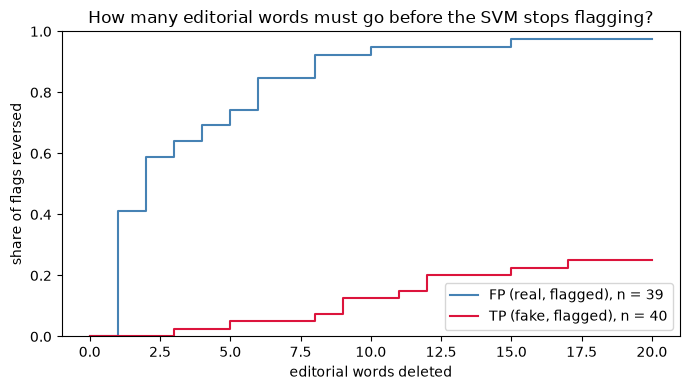

Spearman rho between decision value and editorial counterfactual size (flipped cases, n = 48): 0.82
Median decision value: FP 0.25 | TP 1.25


In [19]:
def cf_summary(g):
    return pd.Series({
        "n": len(g),
        "flipped within 20 (any word)": g.cf_size_any.notna().mean(),
        "median size (any word)": g.cf_size_any.median(),
        "flipped within 3 (any word)": (g.cf_size_any <= 3).mean(),
        "uses a fingerprint word": g.cf_any_uses_fingerprint.mean(),
        "flipped within 20 (editorial only)": g.cf_size_editorial.notna().mean(),
        "median size (editorial only)": g.cf_size_editorial.median(),
        "flipped within 3 (editorial only)": (g.cf_size_editorial <= 3).mean(),
    })
cf_table = cf.groupby("group").apply(cf_summary)
display(cf_table.round(3))
RESULTS["counterfactuals"] = cf_table.round(3).to_dict(orient="index")

ks_cf = np.arange(0, MAX_EDITS + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for g, color in [("FP (real, flagged)", "steelblue"), ("TP (fake, flagged)", "crimson")]:
    sizes = cf.loc[cf.group == g, "cf_size_editorial"]
    ax.step(ks_cf, [(sizes <= k).mean() for k in ks_cf], where="post", color=color, label=f"{g}, n = {len(sizes)}")
ax.set_xlabel("editorial words deleted"); ax.set_ylabel("share of flags reversed"); ax.set_ylim(0, 1)
ax.set_title("How many editorial words must go before the SVM stops flagging?"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# Is the counterfactual size just another way of saying how close the article is to the boundary?
both = cf.dropna(subset=["cf_size_editorial"])
rho_margin = spearmanr(both.decision_value, both.cf_size_editorial).correlation
print(f"Spearman rho between decision value and editorial counterfactual size (flipped cases, n = {len(both)}): {rho_margin:.2f}")
print("Median decision value: FP", round(cf.loc[cf.group.str.startswith('FP'), 'decision_value'].median(), 2),
      "| TP", round(cf.loc[cf.group.str.startswith('TP'), 'decision_value'].median(), 2))
RESULTS["counterfactual_margin_spearman"] = float(rho_margin)

**Wrong flags are fragile; right flags are not.**

| | Real articles wrongly flagged (39) | Fakes correctly flagged (40) |
|---|---|---|
| Cleared by deleting 1 editorial word | 41% | 0% |
| Cleared by deleting 3 editorial words or fewer | 64% | 2.5% |
| Typical number of editorial words needed | 2 | 9.5 |
| Not cleared even after 20 editorial words | 3% | 75% |

When fingerprint words may be deleted too, 96% of the fakes' quickest routes use one, usually a photo-credit or link word. So **the easiest way for a fake article to slip past the SVM is to remove its page layout, not to change what it claims.**

The number of words needed is closely tied to how far the article is from the boundary (rank correlation 0.82; typical SVM score 0.25 for wrong flags, 1.24 for right flags). So the counterfactual doesn't add new information, but it says the same thing in a form a reviewer can read: "two words decide this flag" instead of "score 0.25".

In [20]:
# Two worked examples for the report: the false positive and the true positive with the smallest editorial counterfactual
for g in ("FP (real, flagged)", "TP (fake, flagged)"):
    row = cf[cf.group == g].sort_values("cf_size_editorial").iloc[0]
    i = int(row.article)
    print(f"{g} | '{test_title.iloc[i][:80]}' | decision value {row.decision_value:.2f}")
    print(f"   any-word counterfactual ({row.cf_size_any:.0f} words): {row.cf_words_any}")
    print(f"   editorial-only counterfactual ({row.cf_size_editorial:.0f} words): {row.cf_words_editorial}\n")

# Is a small counterfactual a warning sign? Compare how fragile wrong and right flags are.
for k in (1, 2, 3, 5):
    fp_share = (cf.loc[cf.group.str.startswith('FP'), 'cf_size_editorial'] <= k).mean()
    tp_share = (cf.loc[cf.group.str.startswith('TP'), 'cf_size_editorial'] <= k).mean()
    print(f"flag reversed by <= {k} editorial deletions: FP {fp_share:.0%} vs TP {tp_share:.0%}")

FP (real, flagged) | 'Gunman in U.S. massacre described as 'quiet' but grew hateful' | decision value 0.20
   any-word counterfactual (1 words): mateen
   editorial-only counterfactual (1 words): mateen

TP (fake, flagged) | 'PROTESTERS CAN’T STOP A HUMBLE TRUMP: Delivers A Powerful Message To Detroit [Vi' | decision value 0.44
   any-word counterfactual (3 words): detroit, via, american
   editorial-only counterfactual (3 words): detroit, american, thing

flag reversed by <= 1 editorial deletions: FP 41% vs TP 0%
flag reversed by <= 2 editorial deletions: FP 59% vs TP 0%
flag reversed by <= 3 editorial deletions: FP 64% vs TP 2%
flag reversed by <= 5 editorial deletions: FP 74% vs TP 5%


**An example.** The easiest wrong flag to clear is a Reuters report on a mass shooting ("Gunman in U.S. massacre described as 'quiet' but grew hateful"). Deleting a single word, the gunman's surname "mateen", clears the flag. The article was already close to the boundary (score 0.20), and the deciding word is a name tied to one news event, not anything about how the article is written.

**A rule a reviewer could use:** if deleting three or fewer editorial words would clear a flag, send the article to a fact-checker instead of acting on it straight away. On this test set, that rule catches 25 of the 39 wrong flags (64%) and only 1 of the 40 sampled correct flags (2.5%). The threshold of three was chosen after seeing these results, so treat it as a first idea, not a tested rule.

In [21]:
# Does the counterfactual rule sort flags better than a simple cut-off on the SVM score?
fp_cf, tp_cf = cf[cf.group.str.startswith("FP")], cf[cf.group.str.startswith("TP")]
n_fp_rule, n_tp_rule = int((fp_cf.cf_size_editorial <= 3).sum()), int((tp_cf.cf_size_editorial <= 3).sum())
t_same = np.sort(fp_cf.decision_value.to_numpy())[n_fp_rule - 1]            # cut-off that catches as many FPs
n_tp_thr = int((tp_cf.decision_value <= t_same).sum())
from scipy.stats import beta as _beta
lo = _beta.ppf(0.025, n_tp_rule, len(tp_cf) - n_tp_rule + 1) if n_tp_rule else 0.0
hi = _beta.ppf(0.975, n_tp_rule + 1, len(tp_cf) - n_tp_rule)
n_tp_all = int(((y_true == 1) & (svm_pred == 1)).sum())
print(f"Counterfactual rule (<= 3 editorial words): routes {n_fp_rule}/{len(fp_cf)} FPs and {n_tp_rule}/{len(tp_cf)} sampled TPs")
print(f"Decision-value threshold <= {t_same:.2f} (same number of FPs): routes {n_tp_thr}/{len(tp_cf)} sampled TPs")
print(f"Rule's TP routing rate 95% CI (Clopper-Pearson): {lo:.1%} to {hi:.1%} -> about {n_tp_all * n_tp_rule / len(tp_cf):.0f} "
      f"of all {n_tp_all} true positives (range {n_tp_all * lo:.0f} to {n_tp_all * hi:.0f})")
RESULTS["triage_vs_threshold"] = {"rule_fp": [n_fp_rule, len(fp_cf)], "rule_tp": [n_tp_rule, len(tp_cf)],
                                  "threshold": float(t_same), "threshold_tp": [n_tp_thr, len(tp_cf)],
                                  "rule_tp_rate_ci95": [float(lo), float(hi)], "n_tp_all": n_tp_all}

Counterfactual rule (<= 3 editorial words): routes 25/39 FPs and 1/40 sampled TPs
Decision-value threshold <= 0.29 (same number of FPs): routes 0/40 sampled TPs
Rule's TP routing rate 95% CI (Clopper-Pearson): 0.1% to 13.2% -> about 85 of all 3402 true positives (range 2 to 448)


The rule doesn't sort flags any better than the SVM's score itself. A simple cut-off (send every flag with a score below 0.29 to a fact-checker) catches the same 25 wrong flags and none of the 40 sampled correct ones. Across all 3,402 correct flags, the rule's 1-in-40 rate would send about 85 real fakes for checking (range 2 to 448, since 40 is a small sample).

So the counterfactual's value isn't better sorting. It's a **reason the reviewer can check**: it names the two or three words a flag depends on, so the reviewer can judge whether they're meaningful content or just a passing name.

## 6. Do Mistakes Cluster on Articles About Protected Groups?

The dataset has no information about people: no author, age, gender or location. But articles do *mention* protected groups. Some top words are also partisan (hillary, gop), which can stand in for political opinion, a specially protected category under the GDPR (Article 9).

We mark articles that mention a religion, an ethnic group or immigration, using a short keyword list, and check two things:

- whether the SVM makes more mistakes on those articles (real articles wrongly flagged, fake articles missed);
- how strongly the top words appear together with those mentions. The score (phi) runs from 0 (no link) to 1 (always together).

The keyword lists are rough, so this is a screening check, not a full fairness audit.

In [22]:
GROUPS = {
    "religion": r"\b(?:muslims?|islam|islamic|christians?|christianity|jews|jewish|judaism|catholics?|mosques?|church(?:es)?)\b",
    "race_ethnicity": r"\b(?:black people|african americans?|hispanics?|latinos?|latinas?|asian americans?|racial|racism|racist)\b",
    "immigration": r"\b(?:immigrants?|immigration|refugees?|migrants?|undocumented|illegal aliens?)\b",
}
raw_lower = test_raw.str.lower()
flags = pd.DataFrame({g: raw_lower.str.contains(p, regex=True).to_numpy() for g, p in GROUPS.items()})
flags["any_group"] = flags.any(axis=1)

rows = []
for g in flags.columns:
    for label, err_name, err in [(0, "FPR (real flagged as fake)", svm_pred == 1), (1, "FNR (fake missed)", svm_pred == 0)]:
        m = y_true == label
        w, wo = m & flags[g].to_numpy(), m & ~flags[g].to_numpy()
        rows.append({"group mention": g, "error": err_name,
                     "rate with mention": err[w].mean(), "errors / n with": f"{int(err[w].sum())} / {int(w.sum())}",
                     "rate without": err[wo].mean(), "errors / n without": f"{int(err[wo].sum())} / {int(wo.sum())}"})
err_tab = pd.DataFrame(rows)
display(err_tab.round(4))
RESULTS["ethics_error_rates"] = err_tab.round(4).to_dict(orient="records")

top_shap_terms = ["said", "via", "image", "video", "hillary", "featured", "even", "gop", "reuters", "minister"]
present = pd.DataFrame({t: (X_test[:, vocab[t]].toarray().ravel() > 0) for t in top_shap_terms})
phi = pd.DataFrame({g: [np.corrcoef(present[t], flags[g])[0, 1] for t in top_shap_terms] for g in flags.columns},
                   index=top_shap_terms)
display(phi.round(3))
print("Largest |phi|:", phi.abs().stack().idxmax(), round(phi.abs().stack().max(), 3))
RESULTS["ethics_phi_max"] = {"pair": list(phi.abs().stack().idxmax()), "phi": float(phi.abs().stack().max())}

,group mention,error,rate with mention,errors / n with,rate without,errors / n without
0,religion,FPR (real flagged as fake),0.0118,10 / 848,0.0086,29 / 3390
1,religion,FNR (fake missed),0.0267,17 / 636,0.0245,70 / 2853
2,race_ethnicity,FPR (real flagged as fake),0.0364,4 / 110,0.0085,35 / 4128
3,race_ethnicity,FNR (fake missed),0.0070,4 / 573,0.0285,83 / 2916
4,immigration,FPR (real flagged as fake),0.0140,8 / 573,0.0085,31 / 3665
5,immigration,FNR (fake missed),0.0410,17 / 415,0.0228,70 / 3074
6,any_group,FPR (real flagged as fake),0.0118,14 / 1182,0.0082,25 / 3056
7,any_group,FNR (fake missed),0.0256,31 / 1211,0.0246,56 / 2278


,religion,race_ethnicity,immigration,any_group
said,0.075,-0.070,0.044,0.038
via,0.033,0.221,-0.006,0.109
image,0.010,0.250,-0.049,0.089
video,0.013,0.140,-0.015,0.059
hillary,-0.039,0.088,0.030,0.006
featured,-0.001,0.257,-0.056,0.082
even,0.029,0.145,0.056,0.096
gop,-0.001,0.132,0.010,0.052
reuters,0.063,-0.069,0.065,0.045
minister,0.069,-0.097,0.020,0.027


Largest |phi|: ('featured', 'race_ethnicity') 0.257


**Some mistakes happen more often on articles about protected groups:**

- **Race or ethnicity:** real articles that mention it are wrongly flagged 3.6% of the time (4 of 110), against 0.85% for other real articles.
- **Religion and immigration:** real articles mentioning them are flagged slightly more often too, and fake articles about immigration are missed more often (4.1%, 17 of 415, against 2.3%).

The numbers are small, so we don't claim these differences are significant. But the direction makes sense: the photo-credit words that most strongly signal "fake" appear together with race-related mentions (phi up to 0.26), because in this dataset the fake sites write about race more than Reuters does. So a real article about race starts closer to the boundary. Partisan names (hillary, gop) are themselves top words and can stand in for political opinion.

**For a reviewer:** flags on articles about protected groups or partisan topics deserve a human check before acting.

## 7. One Figure for the Report

The three main results in one figure: (a) deleting LIME's top words vs random words (faithfulness), (b) how much explanations change across seeds and small edits (stability), and (c) how many editorial words it takes to clear a flag (actionability).

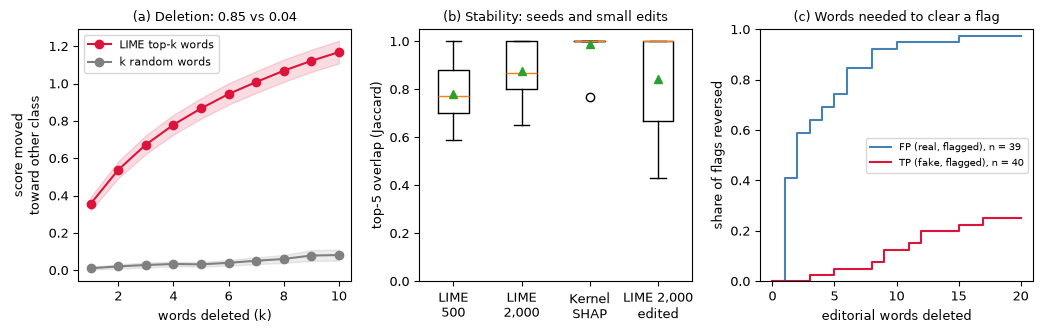

In [23]:
plt.rcParams.update({"font.size": 9})               # sized for a full-width figure in a printed report
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
m_l, m_r = curves_lime.mean(axis=0), curves_rand.mean(axis=0)
se_l, se_r = curves_lime.std(axis=0, ddof=1) / np.sqrt(len(curves_lime)), curves_rand.std(axis=0, ddof=1) / np.sqrt(len(curves_rand))
axes[0].plot(ks, m_l, marker="o", color="crimson", label="LIME top-k words")
axes[0].fill_between(ks, m_l - 1.96 * se_l, m_l + 1.96 * se_l, color="crimson", alpha=0.15)
axes[0].plot(ks, m_r, marker="o", color="grey", label="k random words")
axes[0].fill_between(ks, m_r - 1.96 * se_r, m_r + 1.96 * se_r, color="grey", alpha=0.15)
axes[0].set_xlabel("words deleted (k)"); axes[0].set_ylabel("score moved\ntoward other class")
axes[0].set_title(f"(a) Deletion: {aopc_lime.mean():.2f} vs {aopc_rand.mean():.2f}", fontsize=9.5); axes[0].legend(fontsize=8)
axes[1].boxplot(vals, tick_labels=["LIME\n500", "LIME\n2,000", "Kernel\nSHAP", "LIME 2,000\nedited"], showmeans=True)
axes[1].set_ylabel("top-5 overlap (Jaccard)"); axes[1].set_ylim(0, 1.05)
axes[1].set_title("(b) Stability: seeds and small edits", fontsize=9.5)
for g, color in [("FP (real, flagged)", "steelblue"), ("TP (fake, flagged)", "crimson")]:
    sizes = cf.loc[cf.group == g, "cf_size_editorial"]
    axes[2].step(ks_cf, [(sizes <= k).mean() for k in ks_cf], where="post", color=color, label=f"{g}, n = {len(sizes)}")
axes[2].set_xlabel("editorial words deleted"); axes[2].set_ylabel("share of flags reversed"); axes[2].set_ylim(0, 1)
axes[2].set_title("(c) Words needed to clear a flag", fontsize=9.5); axes[2].legend(loc="center right", fontsize=7.5)
plt.tight_layout(); plt.show()
plt.rcParams.update({"font.size": 10})

## 8. All Numbers in One Place

Every number used in this notebook, printed together so the report can be checked against it.

In [24]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o
print(json.dumps(to_jsonable(RESULTS), indent=2))

{
  "random_state": 42,
  "performance": {
    "Logistic regression (baseline)": {
      "fake_recall": 0.969,
      "precision": 0.9872,
      "accuracy": 0.9803,
      "roc_auc": 0.9978,
      "TP": 3381,
      "FN": 108,
      "FP": 44,
      "TN": 4194
    },
    "Decision tree (depth 3)": {
      "fake_recall": 0.9229,
      "precision": 0.8344,
      "accuracy": 0.8825,
      "roc_auc": 0.9361,
      "TP": 3220,
      "FN": 269,
      "FP": 639,
      "TN": 3599
    },
    "SVM, RBF kernel (tested model)": {
      "fake_recall": 0.9751,
      "precision": 0.9887,
      "accuracy": 0.9837,
      "roc_auc": 0.9984,
      "TP": 3402,
      "FN": 87,
      "FP": 39,
      "TN": 4199
    }
  },
  "svm_vs_lr": {
    "discordant_all": [
      7,
      33
    ],
    "mcnemar_p_all": 4.2277022657799534e-05,
    "discordant_fake": [
      3,
      24
    ],
    "mcnemar_p_fake": 4.9233436584472656e-05,
    "recall_diff": 0.006018916595012969,
    "recall_diff_ci95": [
      0.0031527658354